# Un Problema de control para la operación de trenes.


## Opjetivos principales 
- Aspectos de controlabilidad y observabilidad del modelo.
- investigar $w$ las fuerzas de disipación.
- Programar el modelo en Julia con OptimalControl
- Analizar variantes del problema, como considerar distintas masas o minimizar potencia y energia???
- Implementar el algoritmo de Khmelnitsky, las ecuaciones de HJB nos dicen algo más? comparar resultados con OptCon


## La dinámica

Se considera el tren como un punto singular con masa. Se plantea la siguiente dinámica para las fuerzas:

$$
dinámica
$$

asociada a las condiciones de borde y del control:
$$
restricciones de borde y de control
$$
explicación

Se cambia la dependencia del tiempo por la espacial, 

Para obtener propiedades analíticas sobre la trayectoria óptima se estudia la aplicación del principio del máximo de Pontryagin:

## El principio del máximo

Se plantea el Hamiltoneano del problema:

$$
Hamiltoneano
$$
$$
propiedades del dual?
$$

notamos que las funciones no dependen de $t(s)$ por lo que las variables del co-estado son constantes.
Los régimenes de estabilización, tanto de frenado como de tracción, son singulares, porque su control no viene directamente de la maximización del Hamiltoneano.

En estos estados, la energía cinética se mantiene constante. por las condiciones sobre el control, estos régimenes solo pueden ocurrir cuando se satisface:
$$
0 \leq \dot{P}+w(K_s) \leq g_{tr}(K_s)
$$
Esto será llamado un "minor grade" para el acelerado, y un "steep fall" en caso del frenado.
el algoritmo se basa en buscar los posibles puntos de entrada y salida de estos intervalos intervalos, unirlos con "linking functions", dadas por la ecuación de estado y co-estado entre los régimenes de estabilización.



blas y blas
no se q aser

## Un primer acercamiento

En primera instancia, resolveremos el problema de control óptimo con los recursos que ya manejamos del curso, valiéndonos de OptimalControl y sin entrar en ningun tipo de análisis.


▫ This is OptimalControl 2.0.4, solving with: collocation → adnlp → ipopt (cpu)

  📦 Configuration:
   ├─ Discretizer: collocation
   ├─ Modeler: adnlp
   └─ Solver: ipopt

▫ This is Ipopt version 3.14.19, running with linear solver MUMPS 5.9.0.

Number of nonzeros in equality constraint Jacobian...:     2004
Number of nonzeros in inequality constraint Jacobian.:      502
Number of nonzeros in Lagrangian Hessian.............:      501

Total number of variables............................:     1002
                     variables with only lower bounds:      751
                variables with lower and upper bounds:        0
                     variables with only upper bounds:        0
Total number of equality constraints.................:      504
Total number of inequality constraints...............:      502
        inequality constraints with only lower bounds:        0
   inequality constraints with lower and upper bounds:        0
        inequality constraints with only upper b

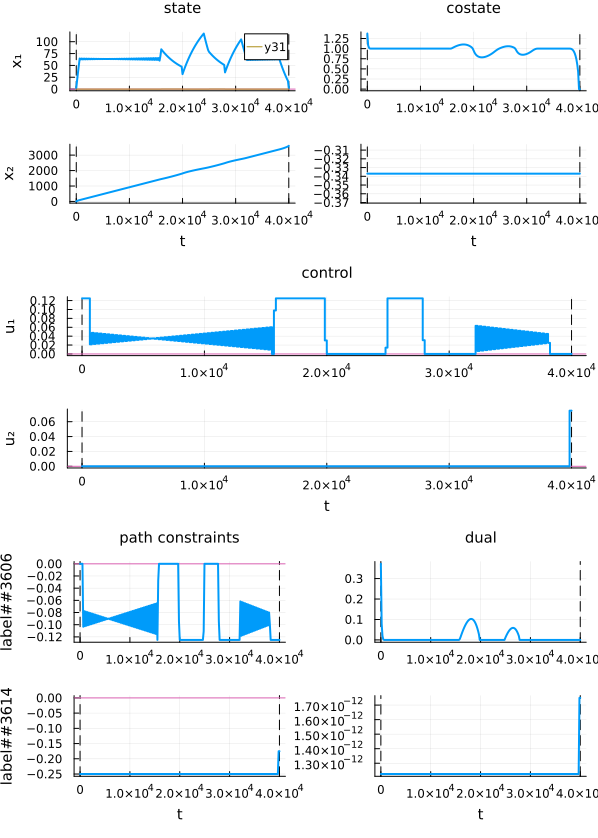

In [37]:
using OptimalControl
using NLPModelsIpopt
using Plots
using IntervalSets

### Funciones dadas
# Energía potencial (pendientes) (ilustrativo)
function P(x)
    # funcion definida de 0 a 40k metros con una montañita centrada en 25km
    if x in 0..16000
        return 0
    elseif x in 16000..25000
        return 23*(x-16000)/450
    elseif x in 25000..40000
        return 460-23*(x-25000)/750
    else return 0
    end
end

function dP(x) # Funcion que se usa realmetne, está actualmente adaptada al ejemplo 1 del paper y no corresponde con P
    if x in 16000..20000
        return 0.1
    elseif x in 20000..24000
        return -0.06
    elseif x in 25000..28000
        return 0.1
    elseif x in 28000..31000
        return -0.06
    else return 0
    end
end

# Fuerza de tracción y frenado (break) máximos
gtr(s) = 0.125
gb(s) = 0.25
# fuerzas de disipación (cambiar factores a,b,c no negativos)
a,b,c = 0.015, 0.0012, 0.00016
w(K) = a + b*sqrt(K) + c*K
# "recovery factor" retorno de energía al frenar ∈[0,1]
α = 0.0

### Condiciones iniciales
E₀ = 2
Eₛ = 2
T = 3600 #?
S = 40000

ocp = @def begin
    t ∈ [0, S], time # en verdad es la variable espacial
    x ∈ R^2, state # x[1]: Energía kinética, E = K + P, por lo que necesitamos plantear Ṗ en la dinámica
                   # x[2]: tiempo, 
    u ∈ R^2, control

    # Condiciones iniciales y finales
    x(0) == [E₀, 0]
    x(S) == [Eₛ, T]  # debo llegar con energía Eₛ en tiempo T

    # Condición sobre la energía
    x[1](t) ≥ 1e-2

    # restricciones sobre el control
    u[1](t) ≥ 0
    u[1](t) - gtr( x[1](t)) ≤ 0

    u[2](t) ≥ 0
    u[2](t) - gb( x[1](t)) ≤ 0

    # Dinámica
    ẋ(t) == [(u[1](t) - u[2](t) - w(x[1](t)) - dP(t)), 1/(sqrt(2x[1](t)))]
    ∫( u[1](t) - α*u[2](t)) → min
end

sol = solve(ocp)
plot(sol)

plot!(dP, range(1,40000))

### Resultados
Cambiando los parámetros de los limites gr observamos los resultados que plantea el paper sobre los intervalos de estabilización, y que con suficiente libertad sobre el control, los "stabilization regimes"  dan velocidades constantes, (K constante).
Para los mismos parámetros del ejemplo 1 a), logramos replicar (al menos visualmente) los resultados sobre el perfil de energía kinética del paper.

Ahondamos sobre las mejoras, utilizando optimal control, obtenemos resultados consistentes, y tiene una facilidad mucho mayor en la implementación, el algormtmo del paper debe considerar cambios considerables para los casos $\alpha \in \{0,1\}.$ Igualmente se deben hacer modificaciones para considerar cotas dinámicas sobre la velocidad ($K(s)<$).

Estas son ventajas que tiene la implementación en Julia, ya que todas estas cosas se pueden añadir fácilemtne con un par de lineas de código dentro de la implementación, donde se queda corto esto es que necesita más poder computacional, el paper dice que la simplicidad computacional de la implementación permite que se pueda correr en procesadores internos de cada tren, y que se puede hacer de forma dinámica, sin embargo esto ya no es una ventaja tan predonimante considerando los gigantescos pasos en capacidad computacional y la capacidad de centralizar estos cálculos al manejar los trenes de forma remota.

Nos resta intentar implementar el algoritmo planteado del paper para poder corroborar más resultados en ambos casos.


